# SCRO On-Chip Inductor: Laws, Optimization & Two-Layer Stacked Inductance

## Notebook Structure & Workflow

1. **Governing Formulas & Geometry**:
   - The **Modified Wheeler Expression** for planar spiral inductance.
   - Exact geometric equations for inner diameter $d_{\text{in}}$, average diameter $d_{\text{avg}}$, and fill factor $\rho$.
   - Centralized process rules and layout configuration variables ($w, s, d_{\text{out}}, d_{\text{in,min}}$).
2. **Computational Parameter Optimization (Method 1: Grid Search)**:
   - Discrete parameter sweep over turn count $n$ with step size $\Delta n$ under physical core via clearance constraints ($d_{\text{in}} \ge d_{\text{in,min}}$).
   - Comparative evaluation across planar layout shapes (Square, Hexagonal, Octagonal) to locate the global maximum single-layer inductance $L_{\text{max}}$ and optimal turn count $n^*$.
3. **Two-Layer Stacked Inductor Circuit (Final Expected Value)**:
   - Mutual inductance law: $M = k\sqrt{L_1 L_2} = k L_{\text{max}}$.
   - Series-aiding coupled inductance law: $L_{\text{Total}} = L_1 + L_2 + 2M = 2(1 + k) L_{\text{max}}$.
   - Dynamically evaluates effective stacked inductance across varying vertical magnetic coupling factors $k$.
4. **Measuring Steps & Resistor Matching**:
   - De-embedding fixture parasitics: $L(\text{Inductor}) = |L_T - L_0|$.
   - Resistor matching law: $R \approx X_L = 2\pi f L_{\text{Total}}$ targeting a clean $45^\circ$ phase shift for peak measurement sensitivity.
   - Computes required sensing resistors across bench frequencies and the exact target frequency for standard $50\,\Omega$ RF equipment.

---

## Governing Laws from Document

### 1. Modified Wheeler Expression (Page 1)
$$L = \mu_0 \frac{K_1 n^2 d_{\text{avg}}}{1 + K_2 \rho}$$

- **Vacuum Permeability**: $\mu_0 = 4\pi \times 10^{-7} \ \text{H/m} \approx 1.2566 \times 10^{-6}\ \text{H/m}$
- **Inner Core Boundary**: $d_{\text{in}} = d_{\text{out}} - 2 [n w + (n - 1) s]$
- **Average Diameter**: $d_{\text{avg}} = \frac{d_{\text{out}} + d_{\text{in}}}{2}$
- **Fill Factor**: $\rho = \frac{d_{\text{out}} - d_{\text{in}}}{d_{\text{out}} + d_{\text{in}}}$
- **Table I (Coefficients by Layout)**:
  | Layout | $K_1$ | $K_2$ |
  | :--- | :---: | :---: |
  | **Square** | **2.34** | **2.75** |
  | **Hexagonal** | **2.33** | **3.82** |
  | **Octagonal** | **2.25** | **3.55** |

### 2. Physical Layout Constraints (Page 1)
- Line width: $w$ (lithographic metal trace width)
- Line spacing: $s$ (inter-turn dielectric spacing)
- Maximum footprint / outer dimension: $d_{\text{out}}$
- Minimum inner hole clearance: $d_{\text{in}} \ge d_{\text{in,min}}$ (enforcing center via and return trace DRC)

### 3. Mutual Inductance Laws (Page 2)
- Mutual Inductance: $M = k\sqrt{L_1 L_2} \quad (0 < k < 1)$
- Series-Aiding Coupled Inductance: $L_{\text{Total}} = L_1 + L_2 + 2M = 2(1 + k) L_1$

### 4. Measuring Steps & Resistor Matching (Page 2)
- Baseline fixture calibration: $L_0$
- Total circuit measurement: $L_T$
- De-embedded inductor value: $L(\text{Inductor}) = |L_T - L_0|$
- Resistor matching law: $R \approx X_L = 2\pi f L_{\text{Total}}$ targeting $\theta = 45^\circ$ where phase measurement accuracy is highest.

In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Physical constants
mu_0 = 4.0 * np.pi * 1e-7  # Vacuum permeability (H/m)

# Table I: Coefficients for Modified Wheeler Expression
WHEELER_COEFFICIENTS = {
    'Square':    {'K1': 2.34, 'K2': 2.75},
    'Hexagonal': {'K1': 2.33, 'K2': 3.82},
    'Octagonal': {'K1': 2.25, 'K2': 3.55}
}

# ==============================================================================
# USER-CONFIGURABLE DESIGN & PROCESS PARAMETERS
# Modify these values to evaluate different designs, technologies, or rules.
# Re-running the notebook will automatically recompute all values and figures.
# ==============================================================================
DEFAULT_LINE_WIDTH    = 10.0e-6     # Wire / trace width w (meters) [e.g., 5.0 um]
DEFAULT_SPACING       = 10.0e-6     # Inter-trace spacing s (meters) [e.g., 5.0 um]
MAX_SURFACE_AREA      = 800.0e-6   # Maximum outer dimension d_out (meters) [e.g., 400.0 um]
MIN_CORE_CLEARANCE    = 30.0e-6    # Minimum inner hole d_in for center via DRC (meters) [e.g., 30.0 um]
TURN_SWEEP_STEP       = 0.5        # Discrete turn increment Delta n (turns) [e.g., 0.5 turns]
NOMINAL_COUPLING_K    = 0.85       # Inter-layer vertical magnetic coupling coefficient k
BENCH_TARGET_RESISTOR = 50.0       # Standard test bench sensing resistor R (Ohms)
BASELINE_TEST_TURNS   = 5.0        # Turn count for baseline sanity verification (turns)

# Display active parameters table
display(Markdown(f"""
### Active Design & Process Parameters
| Parameter | Symbol | Configured Value | Unit | Description |
| :--- | :---: | :---: | :---: | :--- |
| **Outer Dimension** | $d_{{\\text{{out}}}}$ | **{MAX_SURFACE_AREA * 1e6:.1f}** | $\\mu\\text{{m}}$ | Maximum allowable inductor footprint |
| **Trace Width** | $w$ | **{DEFAULT_LINE_WIDTH * 1e6:.1f}** | $\\mu\\text{{m}}$ | Cleanroom lithography wire width |
| **Trace Spacing** | $s$ | **{DEFAULT_SPACING * 1e6:.1f}** | $\\mu\\text{{m}}$ | Inter-turn dielectric spacing |
| **Turn Pitch** | $p = w + s$ | **{(DEFAULT_LINE_WIDTH + DEFAULT_SPACING) * 1e6:.1f}** | $\\mu\\text{{m}}$ | Pitch between consecutive turns |
| **Min Core Via Hole** | $d_{{\\text{{in,min}}}}$ | **{MIN_CORE_CLEARANCE * 1e6:.1f}** | $\\mu\\text{{m}}$ | Center via opening DRC constraint |
| **Turn Grid Step** | $\\Delta n$ | **{TURN_SWEEP_STEP}** | turns | Discrete layout turn increment |
| **Coupling Factor** | $k$ | **{NOMINAL_COUPLING_K:.2f}** | - | Nominal 2-layer vertical magnetic coupling |
| **Target Sensing Resistor** | $R_{{\\text{{bench}}}}$ | **{BENCH_TARGET_RESISTOR:.1f}** | $\\Omega$ | Standard RF test bench resistor |
"""))



### Active Design & Process Parameters
| Parameter | Symbol | Configured Value | Unit | Description |
| :--- | :---: | :---: | :---: | :--- |
| **Outer Dimension** | $d_{\text{out}}$ | **800.0** | $\mu\text{m}$ | Maximum allowable inductor footprint |
| **Trace Width** | $w$ | **10.0** | $\mu\text{m}$ | Cleanroom lithography wire width |
| **Trace Spacing** | $s$ | **10.0** | $\mu\text{m}$ | Inter-turn dielectric spacing |
| **Turn Pitch** | $p = w + s$ | **20.0** | $\mu\text{m}$ | Pitch between consecutive turns |
| **Min Core Via Hole** | $d_{\text{in,min}}$ | **30.0** | $\mu\text{m}$ | Center via opening DRC constraint |
| **Turn Grid Step** | $\Delta n$ | **0.5** | turns | Discrete layout turn increment |
| **Coupling Factor** | $k$ | **0.85** | - | Nominal 2-layer vertical magnetic coupling |
| **Target Sensing Resistor** | $R_{\text{bench}}$ | **50.0** | $\Omega$ | Standard RF test bench resistor |


## 1. Variable Generator & Modified Wheeler Inductance

This section implements the function to compute all variables required by the Modified Wheeler formula:
- Coefficients $K_1, K_2$ retrieved from Table I for the selected geometry.
- Inner diameter: $d_{\text{in}} = d_{\text{out}} - 2[nw + (n-1)s]$.
- Average diameter: $d_{\text{avg}} = \frac{d_{\text{out}} + d_{\text{in}}}{2}$.
- Fill factor: $\rho = \frac{d_{\text{out}} - d_{\text{in}}}{d_{\text{out}} + d_{\text{in}}}$.
- Inductance: $L = \mu_0 \frac{K_1 n^2 d_{\text{avg}}}{1 + K_2 \rho}$.

In [22]:
def get_wheeler_variables(shape, n, d_out=MAX_SURFACE_AREA, w=DEFAULT_LINE_WIDTH, s=DEFAULT_SPACING, d_in=None):
    shape_key = shape.capitalize()
    if shape_key not in WHEELER_COEFFICIENTS:
        raise ValueError(f"Shape '{shape}' unknown. Choose from {list(WHEELER_COEFFICIENTS.keys())}")
    
    K1 = WHEELER_COEFFICIENTS[shape_key]['K1']
    K2 = WHEELER_COEFFICIENTS[shape_key]['K2']
    
    if d_in is None:
        d_in = d_out - 2.0 * (n * w + (n - 1.0) * s)
    
    if d_in <= 0:
        raise ValueError(f"Inner diameter d_in ({d_in*1e6:.1f} um) <= 0. Reduce turns n.")
        
    d_avg = 0.5 * (d_out + d_in)
    rho = (d_out - d_in) / (d_out + d_in)
    
    return {
        'shape': shape_key,
        'K1': K1,
        'K2': K2,
        'mu_0': mu_0,
        'n': n,
        'w_m': w,
        's_m': s,
        'd_out_m': d_out,
        'd_in_m': d_in,
        'd_avg_m': d_avg,
        'd_out_um': d_out * 1e6,
        'd_in_um': d_in * 1e6,
        'd_avg_um': d_avg * 1e6,
        'rho': rho
    }

def modified_wheeler_inductance(shape, n, d_out=MAX_SURFACE_AREA, w=DEFAULT_LINE_WIDTH, s=DEFAULT_SPACING, d_in=None):
    v = get_wheeler_variables(shape, n, d_out, w, s, d_in)
    numerator = v['mu_0'] * v['K1'] * (v['n']**2) * v['d_avg_m']
    denominator = 1.0 + v['K2'] * v['rho']
    L_H = numerator / denominator
    L_nH = L_H * 1e9
    return L_H, L_nH, v

# Baseline sanity evaluation across shapes using currently active parameters
baseline_records = []
for sh in ['Square', 'Hexagonal', 'Octagonal']:
    L_H, L_nH, v = modified_wheeler_inductance(sh, n=BASELINE_TEST_TURNS, d_out=MAX_SURFACE_AREA, w=DEFAULT_LINE_WIDTH, s=DEFAULT_SPACING)
    baseline_records.append({
        'Geometry': sh,
        'Turns (n)': BASELINE_TEST_TURNS,
        'd_out (um)': round(v['d_out_um'], 1),
        'd_in (um)': round(v['d_in_um'], 1),
        'd_avg (um)': round(v['d_avg_um'], 1),
        'rho': round(v['rho'], 4),
        'Inductance (nH)': round(L_nH, 2)
    })

df_baseline = pd.DataFrame(baseline_records)

display(Markdown(f"""
### Baseline Sanity Verification ($n = {BASELINE_TEST_TURNS}$ turns)
Evaluating planar inductance with active process parameters ($d_{{\\text{{out}}}} = {MAX_SURFACE_AREA*1e6:.1f}\\,\\mu\\text{{m}}$, $w = {DEFAULT_LINE_WIDTH*1e6:.1f}\\,\\mu\\text{{m}}$, $s = {DEFAULT_SPACING*1e6:.1f}\\,\\mu\\text{{m}}$):
"""))
display(df_baseline)



### Baseline Sanity Verification ($n = 5.0$ turns)
Evaluating planar inductance with active process parameters ($d_{\text{out}} = 800.0\,\mu\text{m}$, $w = 10.0\,\mu\text{m}$, $s = 10.0\,\mu\text{m}$):


,Geometry,Turns (n),d_out (um),d_in (um),d_avg (um),rho,Inductance (nH)
0,Square,5.0,800.0,620.0,710.0,0.1268,38.70
1,Hexagonal,5.0,800.0,620.0,710.0,0.1268,35.02
2,Octagonal,5.0,800.0,620.0,710.0,0.1268,34.61


## 2. Computational Parameter Optimization: Discrete Parameter Sweep (Grid Search)

Analytical calculus ($dL/dx = 0$) treats turn count $n$ as continuous and ignores physical layout quantization. Instead, this section performs a **discrete parameter sweep** across layout turn increments ($\Delta n$) while strictly enforcing the center via clearance rule ($d_{\text{in}} \ge d_{\text{in,min}}$).

### Algorithm:
1. **Feasible Turn Range**:
   $$n \le \frac{d_{\text{out}} + 2s - d_{\text{in,min}}}{2(w + s)}$$
2. **Inductance Evaluation**:
   For each candidate $n \in \{1.0, 1.0 + \Delta n, 1.0 + 2\Delta n, \dots\}$:
   $$d_{\text{in}} = d_{\text{out}} - 2[nw + (n-1)s], \quad d_{\text{avg}} = \frac{d_{\text{out}} + d_{\text{in}}}{2}, \quad \rho = \frac{d_{\text{out}} - d_{\text{in}}}{d_{\text{out}} + d_{\text{in}}}$$
   $$L(n) = \mu_0 \frac{K_1 n^2 d_{\text{avg}}}{1 + K_2 \rho}$$
3. **Optimum Selection**:
   $$n^* = \arg\max_{d_{\text{in}} \ge d_{\text{in,min}}} L(n)$$


### Computational Parameter Sweep Results
- **Active Process Parameters:** $d_{\text{out}} = 800.0\,\mu\text{m}$, $w = 10.0\,\mu\text{m}$, $s = 10.0\,\mu\text{m}$ (Pitch $p = 20.0\,\mu\text{m}$)
- **Feasible Turn Range:** $n \in [1.0, 19.75]$ (enforcing $d_{\text{in}} \ge 30.0\,\mu\text{m}$)
- **Theoretical Geometric Limit ($d_{\text{in}} = 0$):** $n_{\text{limit}} = 20.50$ turns


,Shape,K1,K2,Optimal Turns (n*),Outer Dia d_out (um),Inner Dia d_in* (um),Avg Dia d_avg* (um),Fill Factor rho*,Max Inductance L_max (nH)
0,Square,2.34,2.75,17.5,800.0,120.0,460.0,0.7391,136.60
1,Hexagonal,2.33,3.82,17.0,800.0,140.0,470.0,0.7021,108.01
2,Octagonal,2.25,3.55,17.0,800.0,140.0,470.0,0.7021,109.96



> **Optimization Conclusion:** The **Square** layout achieves the highest planar inductance:
> - **Optimal Turns ($n^*$):** **17.5 turns**
> - **Maximum Inductance ($L_{\text{max}}$):** **136.60 nH**
> - **Inner Hole Diameter ($d_{\text{in}}^*$):** **120.0 $\mu\text{m}$** (Clearance margin: **90.0 $\mu\text{m}$** above 30.0 $\mu\text{m}$ DRC limit)
> - **Average Diameter ($d_{\text{avg}}^*$):** **460.0 $\mu\text{m}$**
> - **Fill Factor ($\rho^*$):** **0.7391**


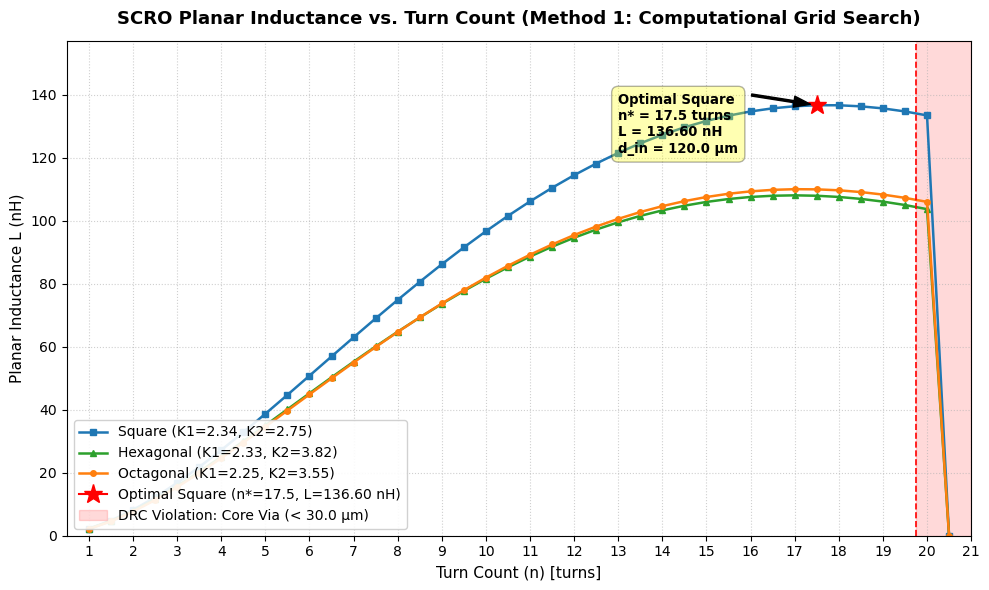

In [23]:
def sweep_optimize_inductance(shape, d_out=MAX_SURFACE_AREA, w=DEFAULT_LINE_WIDTH, s=DEFAULT_SPACING, step=TURN_SWEEP_STEP, d_in_min=MIN_CORE_CLEARANCE, verbose=False):
    shape_key = shape.capitalize()
    if shape_key not in WHEELER_COEFFICIENTS:
        raise ValueError(f"Unknown shape '{shape}'. Choose from: {list(WHEELER_COEFFICIENTS.keys())}")
    
    coeffs = WHEELER_COEFFICIENTS[shape_key]
    K1, K2 = coeffs['K1'], coeffs['K2']
    
    p = w + s
    n_max_geom = (d_out + 2.0 * s) / (2.0 * p)
    candidate_turns = np.arange(1.0, n_max_geom + 0.01, step)
    
    records = []
    best_record = None
    best_L = -1.0
    
    for n in candidate_turns:
        d_in = d_out - 2.0 * (n * w + (n - 1.0) * s)
        d_avg = 0.5 * (d_out + d_in)
        rho = (d_out - d_in) / (d_out + d_in) if (d_out + d_in) > 0 else 0.0
        
        is_feasible = (d_in >= d_in_min)
        if d_in > 0 and (1.0 + K2 * rho) > 0:
            L_H = mu_0 * (K1 * (n**2) * d_avg) / (1.0 + K2 * rho)
            L_nH = L_H * 1e9
        else:
            L_H = 0.0
            L_nH = 0.0
            
        rec = {
            'Turns (n)': round(n, 2),
            'd_in (um)': round(d_in * 1e6, 2),
            'd_avg (um)': round(d_avg * 1e6, 2),
            'rho': round(rho, 4),
            'Inductance (nH)': round(L_nH, 2),
            'L_H': L_H,
            'Feasible': is_feasible
        }
        records.append(rec)
        
        if is_feasible and L_H > best_L:
            best_L = L_H
            best_record = rec

    df_sweep = pd.DataFrame(records)
    
    if best_record is None:
        raise ValueError(f"No feasible turn count satisfies d_in >= {d_in_min*1e6:.1f} um with d_out = {d_out*1e6:.1f} um. Relax d_in_min or increase d_out.")
    
    if verbose:
        print(f"=== Computational Parameter Sweep for {shape_key} Geometry ===")
        print(f"  Fixed Constraints : d_out = {d_out*1e6:.1f} um, w = {w*1e6:.1f} um, s = {s*1e6:.1f} um (Pitch p = {p*1e6:.1f} um)")
        print(f"  Grid Sweep Step   : Delta n = {step} turns, Clearance Rule: d_in >= {d_in_min*1e6:.1f} um")
        print(f"  Wheeler Coeffs    : K1 = {K1:.2f}, K2 = {K2:.2f}")
        print(f"  Grid Range        : {len(candidate_turns)} points evaluated ({candidate_turns[0]} to {candidate_turns[-1]} turns)")
        print(f"  Feasible Points   : {df_sweep['Feasible'].sum()} points satisfy d_in >= {d_in_min*1e6:.1f} um")
        print(f"  Optimal Turn (n*) : {best_record['Turns (n)']} turns")
        print(f"  Inner Diameter    : d_in* = {best_record['d_in (um)']:.1f} um (Clearance margin = {best_record['d_in (um)'] - d_in_min*1e6:.1f} um)")
        print(f"  Average Diameter  : d_avg* = {best_record['d_avg (um)']:.1f} um")
        print(f"  Fill Factor       : rho* = {best_record['rho']:.4f}")
        print(f"  Max Inductance    : L_max = {best_record['Inductance (nH)']:.2f} nH")
        print()

    return {
        'Shape': shape_key,
        'K1': K1,
        'K2': K2,
        'Optimal Turns (n*)': best_record['Turns (n)'],
        'Outer Dia d_out (um)': round(d_out * 1e6, 1),
        'Inner Dia d_in* (um)': best_record['d_in (um)'],
        'Avg Dia d_avg* (um)': best_record['d_avg (um)'],
        'Fill Factor rho*': best_record['rho'],
        'Max Inductance L_max (nH)': best_record['Inductance (nH)'],
        'L_max_H': best_record['L_H'],
        'Sweep Data': df_sweep
    }

# Backward compatibility alias
optimize_max_inductance = sweep_optimize_inductance

# Step 1: Run computational sweep across all 3 geometries
opt_results = [sweep_optimize_inductance(sh, d_out=MAX_SURFACE_AREA, w=DEFAULT_LINE_WIDTH, s=DEFAULT_SPACING,
                                         step=TURN_SWEEP_STEP, d_in_min=MIN_CORE_CLEARANCE)
               for sh in ['Square', 'Hexagonal', 'Octagonal']]
df_opt = pd.DataFrame(opt_results).drop(columns=['L_max_H', 'Sweep Data'])

# Identify optimal shape
best_idx = df_opt['Max Inductance L_max (nH)'].idxmax()
best_res = opt_results[best_idx]
best_shape = best_res['Shape']
best_n = best_res['Optimal Turns (n*)']
max_val = best_res['Max Inductance L_max (nH)']
best_din = best_res['Inner Dia d_in* (um)']
best_davg = best_res['Avg Dia d_avg* (um)']
best_rho = best_res['Fill Factor rho*']

# Extract square specifically for stacked inductor
sq_opt = next(r for r in opt_results if r['Shape'] == 'Square')
n_opt_sq = sq_opt['Optimal Turns (n*)']
L_opt_sq = sq_opt['Max Inductance L_max (nH)']
din_opt_sq = sq_opt['Inner Dia d_in* (um)']

# Dynamic Markdown report
p_um = (DEFAULT_LINE_WIDTH + DEFAULT_SPACING) * 1e6
n_geom_limit = (MAX_SURFACE_AREA + 2.0 * DEFAULT_SPACING) / (2.0 * (DEFAULT_LINE_WIDTH + DEFAULT_SPACING))
n_drc_limit = (MAX_SURFACE_AREA + 2.0 * DEFAULT_SPACING - MIN_CORE_CLEARANCE) / (2.0 * (DEFAULT_LINE_WIDTH + DEFAULT_SPACING))

display(Markdown(f"""
### Computational Parameter Sweep Results
- **Active Process Parameters:** $d_{{\\text{{out}}}} = {MAX_SURFACE_AREA*1e6:.1f}\\,\\mu\\text{{m}}$, $w = {DEFAULT_LINE_WIDTH*1e6:.1f}\\,\\mu\\text{{m}}$, $s = {DEFAULT_SPACING*1e6:.1f}\\,\\mu\\text{{m}}$ (Pitch $p = {p_um:.1f}\\,\\mu\\text{{m}}$)
- **Feasible Turn Range:** $n \\in [1.0, {n_drc_limit:.2f}]$ (enforcing $d_{{\\text{{in}}}} \\ge {MIN_CORE_CLEARANCE*1e6:.1f}\\,\\mu\\text{{m}}$)
- **Theoretical Geometric Limit ($d_{{\\text{{in}}}} = 0$):** $n_{{\\text{{limit}}}} = {n_geom_limit:.2f}$ turns
"""))
display(df_opt)

display(Markdown(f"""
> **Optimization Conclusion:** The **{best_shape}** layout achieves the highest planar inductance:
> - **Optimal Turns ($n^*$):** **{best_n} turns**
> - **Maximum Inductance ($L_{{\\text{{max}}}}$):** **{max_val:.2f} nH**
> - **Inner Hole Diameter ($d_{{\\text{{in}}}}^*$):** **{best_din:.1f} $\\mu\\text{{m}}$** (Clearance margin: **{best_din - MIN_CORE_CLEARANCE*1e6:.1f} $\\mu\\text{{m}}$** above {MIN_CORE_CLEARANCE*1e6:.1f} $\\mu\\text{{m}}$ DRC limit)
> - **Average Diameter ($d_{{\\text{{avg}}}}^*$):** **{best_davg:.1f} $\\mu\\text{{m}}$**
> - **Fill Factor ($\\rho^*$):** **{best_rho:.4f}**
"""))

# Step 2: Visualization of Inductance vs. Turn Count
plt.figure(figsize=(10, 6))

colors = {'Square': '#1f77b4', 'Hexagonal': '#2ca02c', 'Octagonal': '#ff7f0e'}
markers = {'Square': 's', 'Hexagonal': '^', 'Octagonal': 'o'}

all_turns = []
all_L = []
for res in opt_results:
    sh = res['Shape']
    df_s = res['Sweep Data']
    all_turns.extend(df_s['Turns (n)'])
    all_L.extend(df_s['Inductance (nH)'])
    plt.plot(df_s['Turns (n)'], df_s['Inductance (nH)'], label=f"{sh} (K1={res['K1']}, K2={res['K2']})",
             color=colors[sh], marker=markers[sh], markersize=4, linewidth=1.8)

# Highlight optimal square design point
plt.plot(n_opt_sq, L_opt_sq, marker='*', markersize=14, color='red', label=f'Optimal Square (n*={n_opt_sq}, L={L_opt_sq:.2f} nH)')
plt.annotate(f'Optimal Square\nn* = {n_opt_sq} turns\nL = {L_opt_sq:.2f} nH\nd_in = {din_opt_sq:.1f} µm',
             xy=(n_opt_sq, L_opt_sq), xytext=(max(1.0, n_opt_sq - 4.5), max(5.0, L_opt_sq - 15)),
             arrowprops=dict(facecolor='black', shrink=0.08, width=1.5, headwidth=8),
             bbox=dict(boxstyle='round,pad=0.5', facecolor='yellow', alpha=0.3),
             fontsize=9.5, fontweight='bold')

# DRC Boundary Shading for d_in < d_in_min (n > n_drc_limit)
max_turn_evaluated = max(all_turns)
if n_drc_limit < max_turn_evaluated:
    plt.axvspan(n_drc_limit, max_turn_evaluated + TURN_SWEEP_STEP, color='red', alpha=0.15,
                label=f'DRC Violation: Core Via (< {MIN_CORE_CLEARANCE*1e6:.1f} µm)')
    plt.axvline(n_drc_limit, color='red', linestyle='--', linewidth=1.2)

plt.title('SCRO Planar Inductance vs. Turn Count (Method 1: Computational Grid Search)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Turn Count (n) [turns]', fontsize=11)
plt.ylabel('Planar Inductance L (nH)', fontsize=11)
plt.xlim(0.5, max_turn_evaluated + 0.5)
plt.ylim(0, max(all_L) * 1.15)
tick_step = max(1, int(round(max_turn_evaluated / 20)))
plt.xticks(np.arange(1, int(max_turn_evaluated) + 2, tick_step))
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='lower left', framealpha=0.9)
plt.tight_layout()
plt.show()


## 3. Two-Layer Stacked Square Inductor: Final Expected Inductance

Using the optimal planar geometry identified in Section 2, the **final expected effective inductance** of the two-layer stacked square inductor circuit is determined below.

### Circuit Model: Series-Aiding Connection
In multi-layer IC cleanroom metallization, two identical planar spirals are routed on two adjacent metal layers (Layer 1 and Layer 2) separated by an inter-metal dielectric and connected in series-aiding through a central via array:
- Layer 1: $L_1 = L_{\text{max}}$
- Layer 2: $L_2 = L_{\text{max}}$
- Mutual Inductance: $M = k \sqrt{L_1 L_2} = k L_{\text{max}}$

From the coupled circuit law (Page 2 of document):
$$L_{\text{Total}} = L_1 + L_2 + 2M$$

Substituting $L_1 = L_2 = L_{\text{max}}$:
$$\boxed{L_{\text{Total}} = 2(1 + k) L_{\text{max}}}$$

The boost factor relative to a single planar coil is:
$$\text{Boost Factor} = \frac{L_{\text{Total}}}{L_{\text{max}}} = 2(1 + k)$$

In [24]:
# Extract optimized square inductance dynamically
L1_sq = sq_opt['Max Inductance L_max (nH)']
n_opt_sq = sq_opt['Optimal Turns (n*)']

# Evaluate across coupling factors k
k_values = [0.70, 0.75, 0.80, 0.85, 0.90, 0.95, 1.00]
stacked_rows = []

for k in k_values:
    M_val = k * L1_sq
    L_eff = 2.0 * (1.0 + k) * L1_sq
    stacked_rows.append({
        'Coupling (k)': k,
        'L1 = L2 (nH)': L1_sq,
        'Mutual M (nH)': round(M_val, 2),
        'Effective Stacked L (nH)': round(L_eff, 2),
        'Boost Factor': f"{2.0 * (1.0 + k):.2f}x"
    })

df_stacked_sq = pd.DataFrame(stacked_rows)

# Final values at nominal coupling k
k_nom = NOMINAL_COUPLING_K
L_final_nH = 2.0 * (1.0 + k_nom) * L1_sq
M_final_nH = k_nom * L1_sq

display(Markdown(f"""
### Final Expected Effective Inductance: Two-Layer Stacked Inductor
Coupling two identical optimal square spirals ($L_1 = L_2 = {L1_sq:.2f}\\,\\text{{nH}}$ at $n^* = {n_opt_sq}$ turns):
"""))
display(df_stacked_sq)

display(Markdown(f"""
> **Nominal Operating Condition ($k = {k_nom:.2f}$):**
> - **Single-Layer Inductance ($L_1 = L_2$):** **{L1_sq:.2f} nH**
> - **Mutual Inductance ($M = k L_1$):** **{M_final_nH:.2f} nH**
> - **Total Effective Inductance ($L_{{\\text{{Total}}}}$):** $\\mathbf{{{L_final_nH:.2f}\\,\\text{{nH}}}}$
> - **Coupling Boost Factor:** $\\mathbf{{{2.0 * (1.0 + k_nom):.2f}\\times}}$ boost over a single-layer coil
"""))



### Final Expected Effective Inductance: Two-Layer Stacked Inductor
Coupling two identical optimal square spirals ($L_1 = L_2 = 136.60\,\text{nH}$ at $n^* = 17.5$ turns):


,Coupling (k),L1 = L2 (nH),Mutual M (nH),Effective Stacked L (nH),Boost Factor
0,0.70,136.6,95.62,464.44,3.40x
1,0.75,136.6,102.45,478.10,3.50x
2,0.80,136.6,109.28,491.76,3.60x
3,0.85,136.6,116.11,505.42,3.70x
4,0.90,136.6,122.94,519.08,3.80x
5,0.95,136.6,129.77,532.74,3.90x
6,1.00,136.6,136.60,546.40,4.00x



> **Nominal Operating Condition ($k = 0.85$):**
> - **Single-Layer Inductance ($L_1 = L_2$):** **136.60 nH**
> - **Mutual Inductance ($M = k L_1$):** **116.11 nH**
> - **Total Effective Inductance ($L_{\text{Total}}$):** $\mathbf{505.42\,\text{nH}}$
> - **Coupling Boost Factor:** $\mathbf{3.70\times}$ boost over a single-layer coil


## 4. Measurement Steps & Resistor Matching for the Final Inductor

This section applies the measurement procedure from Page 2 directly to the final expected inductor circuit.

### Measurement Procedure:
1. **Fixture Calibration**: Measure phase shift across shorted reference probe pads:
   $$L_0 = \text{Baseline fixture parasitic phase / inductance}$$
2. **Circuit Measurement**: Measure phase shift across the fabricated inductor circuit:
   $$L_T = \text{Total measured inductance}$$
3. **De-embedding**: Calculate true device inductance:
   $$L(\text{Inductor}) = |L_T - L_0|$$

---

### Resistor Matching Law (The $45^\circ$ Phase Shift Target):
> *"Match the Resistor: Pick a resistor value close to the expected inductive reactance ($X_L = 2\pi f L$) at your test frequency to target a clean $45^\circ$ phase shift, where measurement accuracy is highest."*

$$\theta = \arctan\left(\frac{X_L}{R}\right) \implies \text{When } R = X_L = 2\pi f L_{\text{Total}}, \ \theta = 45^\circ$$

- **Matched sensing resistor** given test bench frequency $f$:
  $$R_{\text{match}} = 2\pi f L_{\text{Total}}$$
- **Required test frequency** given available standard sensing resistor $R$:
  $$f_{\text{target}} = \frac{R}{2\pi L_{\text{Total}}}$$

In [25]:
def deembed_inductor(L0, LT):
    return abs(L0 - LT)

def match_resistor(L_H, f_Hz):
    return 2.0 * np.pi * f_Hz * L_H

def target_test_frequency(L_H, R_Ohms):
    return R_Ohms / (2.0 * np.pi * L_H)

# Dynamic application to the computed stacked inductor
L_final_H = L_final_nH * 1e-9
R_bench = BENCH_TARGET_RESISTOR

# Compute exact test frequency for standard bench resistor
f_for_bench_Hz = target_test_frequency(L_final_H, R_bench)
f_for_bench_MHz = f_for_bench_Hz / 1e6

# Dynamic bench test frequencies including the exact matched target
bench_frequencies_MHz = sorted(list(set([10.0, round(f_for_bench_MHz, 2), 50.0, 100.0])))
meas_records = []

for f_mhz in bench_frequencies_MHz:
    f_hz = f_mhz * 1e6
    R_matched = match_resistor(L_final_H, f_hz)
    meas_records.append({
        'Test Frequency (MHz)': f_mhz,
        'Expected X_L (Ohms)': round(R_matched, 2),
        'Target Matching Resistor R (Ohms)': round(R_matched, 2),
        'Target Phase Shift': '45.0 deg'
    })

df_meas = pd.DataFrame(meas_records)

display(Markdown(f"""
### Measurement Steps & Resistor Matching for Final Stacked Inductor
- **Device Under Test (DUT) Effective Inductance:** $L_{{\\text{{Total}}}} = {L_final_nH:.2f}\\,\\text{{nH}}$
"""))
display(df_meas)

display(Markdown(f"""
> **Bench Guideline for Standard ${R_bench:.1f}\\,\\Omega$ Sensing Resistor:**
> To target the optimal $45^\\circ$ phase shift (where $X_L = R = {R_bench:.1f}\\,\\Omega$):
> $$f_{{\\text{{target}}}} = \\frac{{R}}{{2\\pi L_{{\\text{{Total}}}}}} = \\frac{{{R_bench:.1f}}}{{2\\pi \\times {L_final_nH:.2f}\\times 10^{{-9}}}} = \\mathbf{{{f_for_bench_MHz:.2f}\\,\\text{{MHz}}}}$$
> At $f = {f_for_bench_MHz:.2f}\\,\\text{{MHz}}$, inductive reactance equals ${R_bench:.1f}\\,\\Omega$, maximizing measurement SNR and sensitivity.
"""))



### Measurement Steps & Resistor Matching for Final Stacked Inductor
- **Device Under Test (DUT) Effective Inductance:** $L_{\text{Total}} = 505.42\,\text{nH}$


,Test Frequency (MHz),Expected X_L (Ohms),Target Matching Resistor R (Ohms),Target Phase Shift
0,10.00,31.76,31.76,45.0 deg
1,15.74,49.98,49.98,45.0 deg
2,50.00,158.78,158.78,45.0 deg
3,100.00,317.56,317.56,45.0 deg



> **Bench Guideline for Standard $50.0\,\Omega$ Sensing Resistor:**
> To target the optimal $45^\circ$ phase shift (where $X_L = R = 50.0\,\Omega$):
> $$f_{\text{target}} = \frac{R}{2\pi L_{\text{Total}}} = \frac{50.0}{2\pi \times 505.42\times 10^{-9}} = \mathbf{15.74\,\text{MHz}}$$
> At $f = 15.74\,\text{MHz}$, inductive reactance equals $50.0\,\Omega$, maximizing measurement SNR and sensitivity.
